# Netflix Movies & TV Shows Data Analysis

## Project Domain:
- Entertainment Analytics
- Data Analytics
- Content Strategy and Business Intelligence

## Project Objective:
- Analyze Netflix movies and TV shows to understand its content library.
- Explore content by type, country, release year, date added, genre, rating, movie durations etc
- Identify and handle missing values and prepare the dataset for analysis.


## Skills:
- Python
- Pandas
- NumPy
- Data Cleaning & Preprocessing
- Missing Value Treatment
- Exploratory Data Analysis (EDA)
- Data Visualization (Matplotlib & Seaborn)
- Insight Generation

## Dataset Information
- Dataset Name: Netflix Movies and TV Shows Dataset (`netflix_titles.csv`)
- Records: 8,807
- Features: 12
- Target Variable:No target variable.

##Key Attributes:
- Content Details: Includes the ID, title, and type of each movie etc.
- Country: Shows the country where the content was produced.
- Release Information: Includes the release year and the date.
- Category and Rating: Tells us the genre of the content and rating.
- Duration: Shows the length of a movie.


# Step 1: Importing Data & Understanding

In [2]:
import pandas as pd
import numpy as np
df = pd.read_csv("netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
print("Shape:", df.shape)
print("Size:", df.size)
print("Dimensions:", df.ndim)

Shape: (8807, 12)
Size: 105684
Dimensions: 2


In [4]:
# Dataset summary
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [5]:
# Statistical summary of numerical columns
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


## Objectives:
- Examine the dataset structure and data types.
- Identify numerical and categorical columns.
- Detect missing values and assess their percentage.
- Review statistical summaries and understand the main characteristics of the data.

# Step 2: Data Cleaning Process

### Missing Data Detection

In [7]:
# Count missing values in each column
df.isnull().sum()

,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3
listed_in,0


In [8]:
# Calculate the percentage of missing values in each column
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_percent

,0
type,0.000000
title,0.000000
director,29.908028
cast,9.367549
country,9.435676
date_added,0.113546
release_year,0.000000
rating,0.045418
duration,0.034064
listed_in,0.000000


### Observations: Missing Columns
- director has the largest number of missing values.
- country and cast also contain missing entries.
- A small number of records are missing from date_added, rating, or duration.

## Missing Data Treatment

In [11]:
#Filling Missing Values
columns = ["director", "cast", "country", "rating", "duration",'date_added']
for i in columns:
    df[i] = df[i].fillna("Unknown")
df.isna().sum()

,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0


###Data Formatting

In [13]:
# Converting values into Pandas Datetime Format.
df['date_added'] = pd.to_datetime(df['date_added'],errors='coerce')#missing value become NAaT or NaN

In [15]:
df['date_added'].dtype

dtype('<M8[ns]')

In [29]:
# Extract year added to Netflix
df["year_added"] = df["date_added"].dt.year

# Step 3: Exploratory Data Analysis (EDA)

## Q1. What is the distribution of Movies and TV Shows?

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

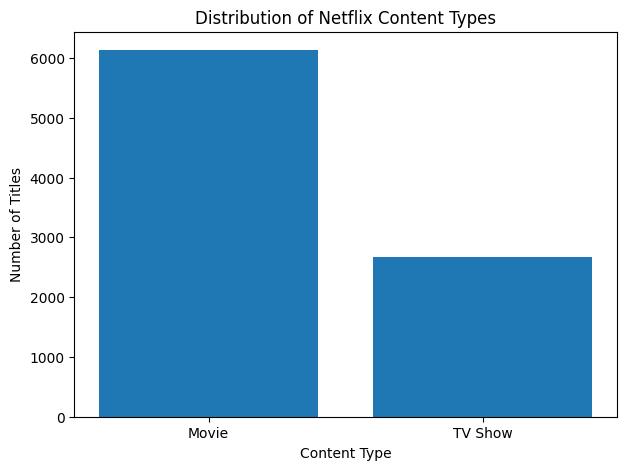

In [17]:
type_counts = df["type"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(type_counts.index, type_counts.values)
plt.title("Distribution of Netflix Content Types")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

### Analysis:
- Movies make up the larger share of the catalogue, at approximately 69.6% of all records.

### Conclusion:
- This dataset contains considerably more Movies than TV Shows.

##Q2. What is the distribution of Netflix content by release year?

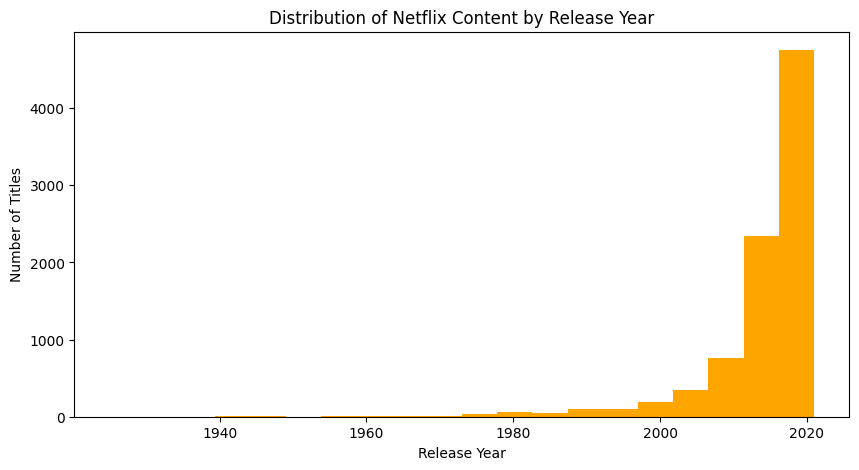

In [19]:
plt.figure(figsize=(10, 5))
plt.hist(df['release_year'], bins=20, color='orange')
plt.title("Distribution of Netflix Content by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

###Analysis:

- The distribution is concentrated largely in the more recent decades, particularly the 2010s.
- Older titles are also present, but they account for a smaller proportion of the catalogue.

###Conclusion:

- It shows that Netflix's catalogue contains a large amount of recent content, particularly titles released during the 2010s.

##Q3. What is the relationship between release year and the year content was added to Netflix?

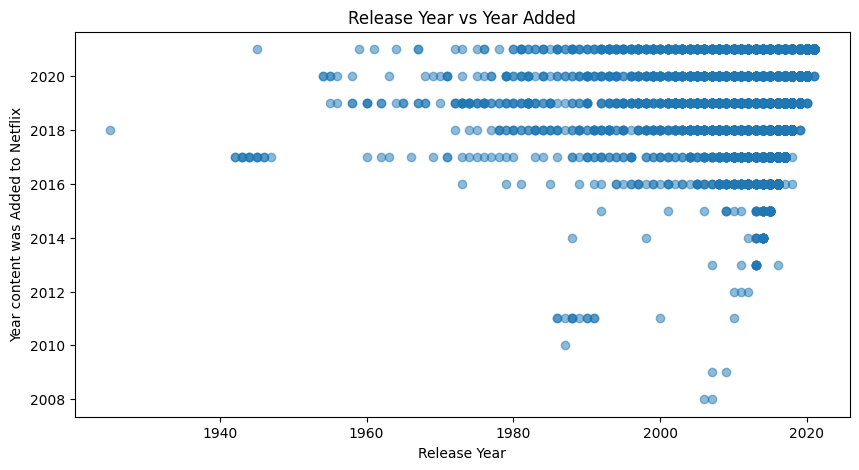

In [31]:
df['year_added'] = df['date_added'].dt.year

plt.figure(figsize=(10,5))

plt.scatter(df['release_year'], df['year_added'], alpha=0.5)

plt.xlabel("Release Year")
plt.ylabel("Year content was Added to Netflix")
plt.title("Release Year vs Year Added")
plt.show()

###Analysis:

- Each point represents a movie or TV Show.
- The graph compares the original release year with the year the title was added to Netflix.

###Conclusion:

- The scatter plot shows that title was released is not necessarily the same as the year it became available on Netflix.

##Q4. Which are the top 10 genres on Netflix?

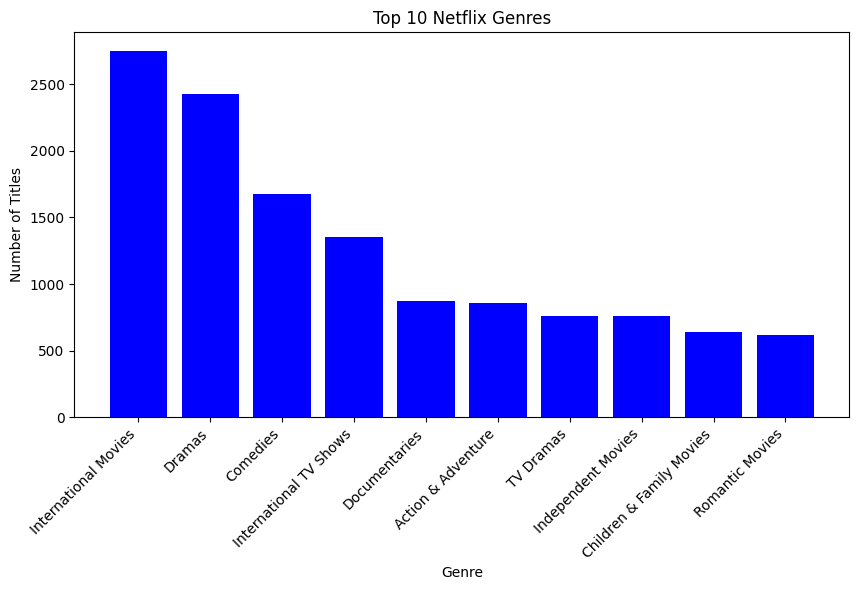

In [41]:
genres = df['listed_in'].dropna().str.split(', ').explode()

top_genres = genres.value_counts().head(10)

plt.figure(figsize=(10, 5))

plt.bar(
    top_genres.index,
    top_genres.values,
    color='blue'
)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha='right')

plt.show()

###Analysis:

- The bar chart displays the 10 most frequently listed categories.
- A title can belong to multiple genres, so one title may contribute to multiple counts.

###Conclusion:

- The graph helps identify the most frequently represented genres: International movies and drama

##Q5.Are there outliers in the release years of Netflix content?

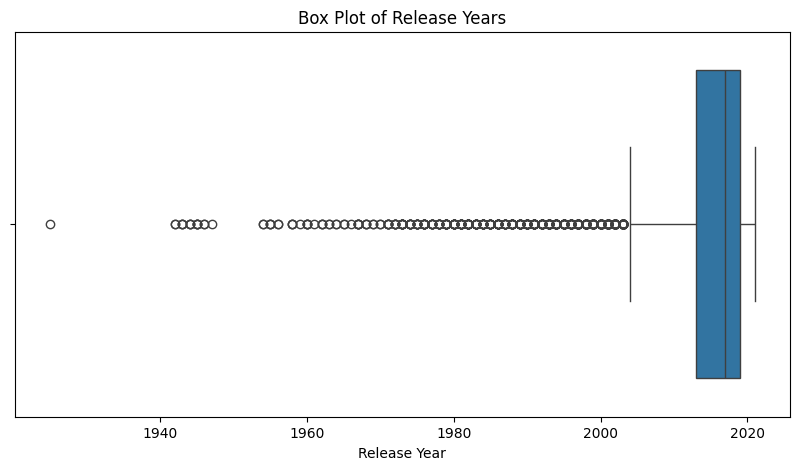

In [48]:
plt.figure(figsize=(10,5))

sns.boxplot(x=df['release_year'])

plt.title("Box Plot of Release Years")
plt.xlabel("Release Year")
plt.show()

###Analysis:

- The box plot shows the distribution of content release years.
- Points outside the whiskers indicate unusually old or recent release years.

###Conclusion:

- Older titles may appear as outliers because the dataset contains a large concentration of more recent releases.

##Q6. How do release years differ between Movies and TV Shows?

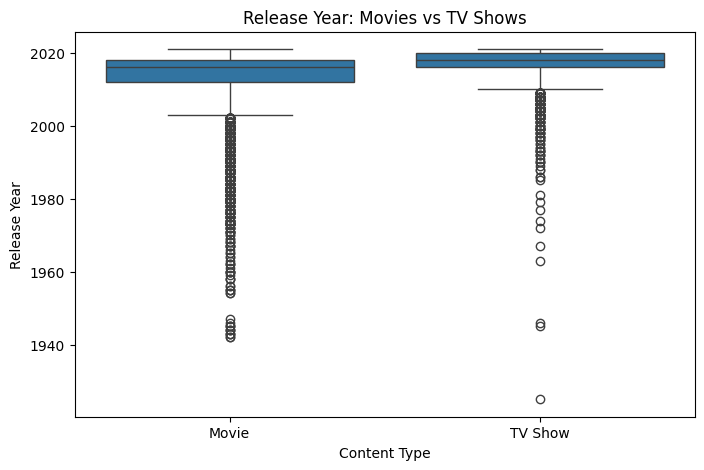

In [49]:
sns.boxplot(data=df,x='type', y='release_year'
)

plt.title("Release Year: Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Release Year")
plt.show()

###Analysis:

- The box plot compares release-year distributions for Movies and TV Shows.
- The outliers show titles released much earlier

###Conclusion
- The box plot helps compare the release years of Movies and TV Shows.
- It shows the median release year, the spread of the data, and any potential outliers

##Q7. What percentage of Netflix content belongs to different content ratings?

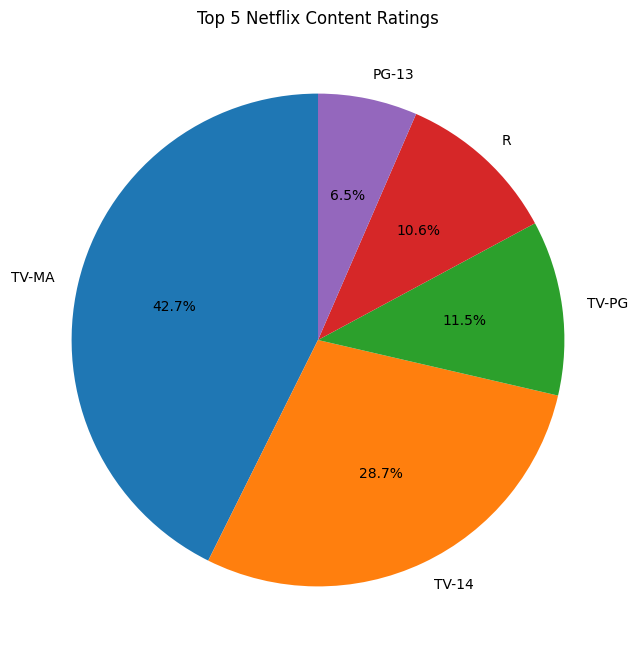

In [54]:
rating_counts = df['rating'].fillna('Unknown').value_counts().head(5)

plt.figure(figsize=(8,8))

plt.pie(
    rating_counts.values,
    labels=rating_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Top 5 Netflix Content Ratings")
plt.show()

###Analysis:

- The pie chart displays the five most common content ratings.
-The percentages are calculated from the combined counts of the five displayed ratings.

###Conclusion:
- The pie chart show around half content falls under mature audiance category

##Q8. What is the correlation between numerical columns?

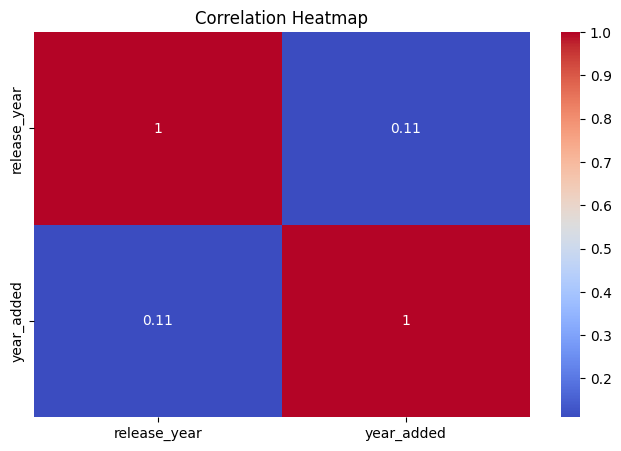

In [57]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df[['release_year','year_added']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()

###Analysis:

- The heatmap displays the correlation between the selected numerical columns.


###Conclusion:

- This show there is not strong relationship between release_year and year_added for older releases.

#Step 4: Data Visualization Dashboard

###Key Insights (Analytics Outcome)
- Movies make up a larger portion of Netflix's content library than TV Shows.
- Popular genres highlight the types of content most frequently available on Netflix.
- Content ratings reveal the different audience categories targeted by Netflix.
- Missing values in columns such as director, cast, and country highlight areas requiring data cleaning.


##Final Conclusion
- This project successfully analyzed Netflix Movies and TV Shows data by examining content types, genres, release years, ratings, and missing values.
- The analysis provided useful insights into Netflix's content distribution and trends, demonstrating how data cleaning and visualization can support better understanding of streaming platform data.